# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Akbar Pradana
- **Email:** akbarprdn2512@gmail.com
- **ID Dicoding:** akbarprdna

## Menentukan Pertanyaan Bisnis

Data berasal dari sistem Capital Bikeshare, Washington D.C., periode 2011 sampai 2012. Analisis dipusatkan ke tahun 2012 karena tahun itu paling dekat dengan kondisi operasional terakhir, sementara 2011 dipakai sebagai pembanding pertumbuhan.

- **Pertanyaan 1:** Sepanjang tahun 2012, berapa persen penurunan rata-rata penyewaan sepeda harian saat cuaca berkabut/berawan dan saat hujan ringan/salju ringan dibanding hari cerah, sehingga operator bisa menentukan berapa unit yang perlu disiagakan dan kapan jadwal perawatan paling aman dilakukan?
- **Pertanyaan 2:** Sepanjang tahun 2012, pada jam berapa rata-rata penyewaan per jam mencapai puncaknya di hari kerja dibanding hari libur/akhir pekan, dan berapa porsi pengguna terdaftar (*registered*) di masing-masing jenis hari, sehingga tim operasional tahu kapan stasiun harus diisi ulang dan segmen mana yang jadi sasaran promosi keanggotaan?

Kedua pertanyaan dibatasi tahun 2012 (*time-bound*), dijawab dengan persentase, rata-rata per jam, dan porsi pengguna (*measurable*), serta langsung terkait keputusan stok sepeda dan jadwal redistribusi (*action-oriented, relevant*).

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["axes.grid.axis"] = "y"  # grid horizontal saja agar tidak menabrak label angka
pd.set_option("display.max_columns", 30)


def rupa(x, desimal=0):
    # Format angka gaya Indonesia: 6.004 dan 16,9
    return f"{x:,.{desimal}f}".replace(",", "_").replace(".", ",").replace("_", ".")

## Data Wrangling

### Gathering Data

In [2]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
print("day_df :", day_df.shape)
print("hour_df:", hour_df.shape)

day_df : (731, 16)
hour_df: (17379, 17)


**Insight:**
- `day.csv` memuat 731 baris (satu baris per hari, 1 Januari 2011 sampai 31 Desember 2012) dan `hour.csv` memuat 17.379 baris (satu baris per jam). Kolomnya sama, kecuali `hr` yang hanya ada di data per jam.
- Data harian dipakai untuk Pertanyaan 1 (cuaca vs penyewaan harian), data per jam untuk Pertanyaan 2 (pola jam). Total `cnt` di kedua tabel nanti dicek harus sama agar keduanya bisa dipakai berdampingan.

### Assessing Data

**Menilai tipe data dan missing value**

In [5]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [6]:
print("Missing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())

Missing value day_df : 0
Missing value hour_df: 0


**Menilai duplikasi**

In [7]:
print("Duplikat day_df :", day_df.duplicated().sum())
print("Duplikat hour_df:", hour_df.duplicated().sum())
print("Tanggal ganda di day_df:", day_df["dteday"].duplicated().sum())

Duplikat day_df : 0
Duplikat hour_df: 0
Tanggal ganda di day_df: 0


**Menilai invalid value lewat statistik deskriptif**

In [8]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [9]:
# Kelembapan 0% tidak masuk akal secara fisik untuk udara luar ruang
print(day_df.loc[day_df["hum"] == 0, ["dteday", "hum", "weathersit", "cnt"]])
print("Jam dengan hum = 0:", (hour_df["hum"] == 0).sum(),
      "pada tanggal", hour_df.loc[hour_df["hum"] == 0, "dteday"].unique())

        dteday  hum  weathersit  cnt
68  2011-03-10  0.0           3  623
Jam dengan hum = 0: 22 pada tanggal <ArrowStringArray>
['2011-03-10']
Length: 1, dtype: str


**Menilai konsistensi antar tabel dan antar kolom**

In [10]:
print("casual + registered != cnt (day) :", (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum())
print("casual + registered != cnt (hour):", (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum())
print("Total cnt day vs hour:", day_df["cnt"].sum(), hour_df["cnt"].sum())

jam_per_hari = hour_df.groupby("dteday").size()
print("Hari dengan jam kurang dari 24:", (jam_per_hari < 24).sum())
print("Total jam yang hilang:", 24 * len(day_df) - len(hour_df))
jam_per_hari[jam_per_hari < 12]

casual + registered != cnt (day) : 0
casual + registered != cnt (hour): 0
Total cnt day vs hour: 3292679 3292679
Hari dengan jam kurang dari 24: 76
Total jam yang hilang: 165


dteday
2011-01-27     8
2012-10-29     1
2012-10-30    11
dtype: int64

In [11]:
print("weathersit day :", day_df["weathersit"].value_counts().sort_index().to_dict())
print("weathersit hour:", hour_df["weathersit"].value_counts().sort_index().to_dict())

weathersit day : {1: 463, 2: 247, 3: 21}
weathersit hour: {1: 11413, 2: 4544, 3: 1419, 4: 3}


**Menilai akurasi label musim**

In [12]:
# Readme menulis 1 = springer, tapi cek bulan mana yang masuk tiap kode
pd.crosstab(day_df["mnth"], day_df["season"])

season,1,2,3,4
mnth,,,,
1,62,0,0,0
2,57,0,0,0
3,40,22,0,0
4,0,60,0,0
5,0,62,0,0
6,0,40,20,0
7,0,0,62,0
8,0,0,62,0
9,0,0,44,16


**Menilai outlier dengan metode IQR**

In [13]:
def hitung_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

for kolom in ["temp", "hum", "windspeed", "casual", "registered", "cnt"]:
    print(f"{kolom:<11}: {hitung_outlier(day_df[kolom])} outlier")

temp       : 0 outlier
hum        : 2 outlier
windspeed  : 13 outlier
casual     : 44 outlier
registered : 0 outlier
cnt        : 0 outlier


**Insight:**
- Tidak ada missing value dan tidak ada baris duplikat di kedua tabel.
- **Tipe data keliru:** `dteday` masih bertipe teks, padahal analisis butuh tipe tanggal. Kolom kategori (`season`, `yr`, `mnth`, `weekday`, `weathersit`) masih berupa kode angka. **Solusi:** ubah `dteday` ke datetime dan petakan kode ke label yang bisa dibaca.
- **Invalid value:** tanggal 2011-03-10 tercatat kelembapan 0 untuk seharian penuh (1 baris harian, 22 baris per jam), padahal hari itu hujan (`weathersit` 3). Udara luar ruang tidak mungkin 0%, jadi ini kesalahan sensor. **Solusi:** ganti dengan rata-rata kelembapan Maret 2011 yang valid.
- **Inconsistent value:** `hour.csv` kehilangan 165 jam dari 76 hari; terparah 2012-10-29 yang cuma punya 1 jam (badai Sandy, menurut Readme dataset). `weathersit` 4 (hujan lebat) hanya muncul 3 kali di data per jam dan tidak ada di data harian. **Solusi:** jam yang hilang tidak diisi, karena kemungkinan besar sistem memang berhenti dan mengisinya dengan angka tebakan akan mengarang permintaan. Kategori 4 digabung ke kategori 3 supaya label cuaca di dua tabel konsisten.
- **Inaccurate value:** Readme menyebut `season` 1 = *springer*, padahal kode 1 berisi Januari, Februari, dan sebagian Maret serta Desember. Kodenya mengikuti musim astronomis Washington D.C. (21 Desember sampai 20 Maret = musim dingin). **Solusi:** beri label sesuai kalender asli: 1 Dingin, 2 Semi, 3 Panas, 4 Gugur.
- **Outlier:** 13 hari punya `windspeed` di atas batas IQR, dan `casual` juga punya outlier. Nilainya masih wajar untuk angin kencang dan lonjakan wisatawan di akhir pekan, jadi **dipertahankan** dan hanya dicatat.
- Total `cnt` di dua tabel sama persis (3.292.679) dan `casual + registered = cnt` di semua baris, jadi kedua tabel konsisten satu sama lain.

### Cleaning Data

**Memperbaiki tipe data tanggal**

In [14]:
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])
day_df["dteday"].dtype, hour_df["dteday"].dtype

(dtype('<M8[us]'), dtype('<M8[us]'))

**Memperbaiki kelembapan 0 pada 2011-03-10**

In [15]:
maret_2011 = (day_df["dteday"].dt.to_period("M") == "2011-03") & (day_df["hum"] > 0)
hum_pengganti = day_df.loc[maret_2011, "hum"].mean()
print("Kelembapan pengganti (ternormalisasi):", round(hum_pengganti, 4))

day_df.loc[day_df["hum"] == 0, "hum"] = hum_pengganti
hour_df.loc[hour_df["hum"] == 0, "hum"] = hum_pengganti
print("Sisa hum = 0 ->", (day_df["hum"] == 0).sum(), (hour_df["hum"] == 0).sum())

Kelembapan pengganti (ternormalisasi): 0.5884
Sisa hum = 0 -> 0 0


**Menyeragamkan kategori cuaca dan memberi label**

In [16]:
hour_df["weathersit"] = hour_df["weathersit"].replace(4, 3)

label_musim = {1: "Dingin", 2: "Semi", 3: "Panas", 4: "Gugur"}
label_cuaca = {1: "Cerah", 2: "Berkabut/Berawan", 3: "Hujan/Salju Ringan"}
label_hari = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}

for df in (day_df, hour_df):
    df["season"] = df["season"].map(label_musim)
    df["weathersit"] = df["weathersit"].map(label_cuaca)
    df["weekday"] = df["weekday"].map(label_hari)
    df["yr"] = df["yr"].map({0: 2011, 1: 2012})
    df["jenis_hari"] = df["workingday"].map({1: "Hari Kerja", 0: "Libur/Akhir Pekan"})
    # Kembalikan nilai ternormalisasi ke satuan asli sesuai Readme dataset
    df["temp_c"] = df["temp"] * 41
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67

print(hour_df["weathersit"].value_counts().to_dict())
day_df[["dteday", "season", "yr", "weathersit", "jenis_hari", "temp_c", "hum_pct", "cnt"]].head()

{'Cerah': 11413, 'Berkabut/Berawan': 4544, 'Hujan/Salju Ringan': 1422}


,dteday,season,yr,weathersit,jenis_hari,temp_c,hum_pct,cnt
0,2011-01-01,Dingin,2011,Berkabut/Berawan,Libur/Akhir Pekan,14.110847,80.5833,985
1,2011-01-02,Dingin,2011,Berkabut/Berawan,Libur/Akhir Pekan,14.902598,69.6087,801
2,2011-01-03,Dingin,2011,Cerah,Hari Kerja,8.050924,43.7273,1349
3,2011-01-04,Dingin,2011,Cerah,Hari Kerja,8.200000,59.0435,1562
4,2011-01-05,Dingin,2011,Cerah,Hari Kerja,9.305237,43.6957,1600


In [17]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        731 non-null    int64         
 1   dteday         731 non-null    datetime64[us]
 2   season         731 non-null    str           
 3   yr             731 non-null    int64         
 4   mnth           731 non-null    int64         
 5   holiday        731 non-null    int64         
 6   weekday        731 non-null    str           
 7   workingday     731 non-null    int64         
 8   weathersit     731 non-null    str           
 9   temp           731 non-null    float64       
 10  atemp          731 non-null    float64       
 11  hum            731 non-null    float64       
 12  windspeed      731 non-null    float64       
 13  casual         731 non-null    int64         
 14  registered     731 non-null    int64         
 15  cnt            731 non-null    int

**Insight:**
- `dteday` sudah bertipe `datetime64`, sehingga bisa difilter per tahun, bulan, dan rentang tanggal di dashboard.
- Kelembapan 0 diganti 0,5884 (sekitar 58,8%, rata-rata Maret 2011). Tidak ada lagi baris dengan kelembapan 0.
- Label cuaca di kedua tabel sekarang sama-sama tiga kategori. Suhu, kelembapan, dan kecepatan angin juga punya kolom versi satuan asli (°C, %, km/jam) agar grafik bisa dibaca orang awam.

## Exploratory Data Analysis (EDA)

### Explore ringkasan parameter statistik

In [18]:
day_df[["temp_c", "hum_pct", "windspeed_kmh", "casual", "registered", "cnt"]].describe().round(1)

,temp_c,hum_pct,windspeed_kmh,casual,registered,cnt
count,731.0,731.0,731.0,731.0,731.0,731.0
mean,20.3,62.9,12.8,848.2,3656.2,4504.3
std,7.5,14.1,5.2,686.6,1560.3,1937.2
min,2.4,18.8,1.5,2.0,20.0,22.0
25%,13.8,52.1,9.0,315.5,2497.0,3152.0
50%,20.4,62.7,12.1,713.0,3662.0,4548.0
75%,26.9,73.0,15.6,1096.0,4776.5,5956.0
max,35.3,97.2,34.0,3410.0,6946.0,8714.0


In [19]:
day_df.groupby("season")["cnt"].mean().reindex(["Dingin", "Semi", "Panas", "Gugur"]).round(0)

season
Dingin    2604.0
Semi      4992.0
Panas     5644.0
Gugur     4728.0
Name: cnt, dtype: float64

In [20]:
day_df.groupby("yr")["cnt"].agg(["sum", "mean", "median", "min", "max"]).round(0)

,sum,mean,median,min,max
yr,,,,,
2011,1243103,3406.0,3740.0,431,6043
2012,2049576,5600.0,5927.0,22,8714


**Insight:**
- Total penyewaan naik dari 1.243.103 (2011) ke 2.049.576 (2012), naik sekitar 65%. Rata-rata harian naik dari 3.406 ke 5.600 sepeda.
- Musim dingin paling sepi (rata-rata sekitar 2.604/hari) dan musim panas paling ramai (sekitar 5.644/hari), cocok dengan label musim yang sudah dikoreksi.
- Karena pertumbuhannya sebesar itu, membandingkan cuaca lintas dua tahun sekaligus akan bias (hari hujan di 2011 otomatis terlihat lebih sepi). Itu alasan Pertanyaan 1 dan 2 dikunci di 2012.

### Explore hubungan cuaca dengan penyewaan harian (Pertanyaan 1)

In [21]:
day_2012 = day_df[day_df["yr"] == 2012]
cuaca_2012 = (day_2012.groupby("weathersit")["cnt"]
              .agg(jumlah_hari="count", rata_rata="mean", median="median")
              .reindex(["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]))
cuaca_2012["selisih_vs_cerah_%"] = (cuaca_2012["rata_rata"] / cuaca_2012.loc["Cerah", "rata_rata"] - 1) * 100
cuaca_2012.round(1)

,jumlah_hari,rata_rata,median,selisih_vs_cerah_%
weathersit,,,,
Cerah,237,6003.7,6398.0,0.0
Berkabut/Berawan,123,4991.3,5191.0,-16.9
Hujan/Salju Ringan,6,2126.2,1598.0,-64.6


In [22]:
day_2012.loc[day_2012["weathersit"] == "Hujan/Salju Ringan", ["dteday", "season", "cnt"]]

,dteday,season,cnt
406,2012-02-11,Dingin,2169
477,2012-04-22,Semi,1027
567,2012-07-21,Panas,4459
640,2012-10-02,Gugur,4639
667,2012-10-29,Gugur,22
725,2012-12-26,Dingin,441


**Insight:**
- Di 2012, hari cerah rata-rata mencatat 6.004 penyewaan. Hari berkabut/berawan turun 16,9% (4.991), sedangkan hari hujan/salju ringan anjlok 64,6% (2.126).
- Kategori hujan/salju ringan hanya terjadi 6 hari di 2012, termasuk 2012-10-29 (badai Sandy, 22 penyewaan). Angka 64,6% perlu dibaca sebagai arah, bukan angka pasti; median 1.598 juga menunjukkan penurunan yang sama tajamnya, jadi temuan ini tidak bergantung pada satu hari ekstrem.

### Explore pola penyewaan per jam (Pertanyaan 2)

In [23]:
hour_2012 = hour_df[hour_df["yr"] == 2012]
pola_jam = hour_2012.pivot_table(index="hr", columns="jenis_hari", values="cnt", aggfunc="mean").round(0)
pola_jam.T

hr,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
jenis_hari,,,,,,,,,,,,,,,,,,,,,,,,
Hari Kerja,44.0,19.0,10.0,5.0,6.0,32.0,128.0,367.0,605.0,302.0,169.0,199.0,254.0,250.0,230.0,256.0,372.0,656.0,617.0,438.0,312.0,229.0,169.0,109.0
Libur/Akhir Pekan,109.0,85.0,63.0,30.0,10.0,10.0,23.0,55.0,135.0,215.0,317.0,392.0,451.0,459.0,448.0,438.0,428.0,395.0,338.0,276.0,208.0,169.0,137.0,101.0


In [24]:
for jenis in ["Hari Kerja", "Libur/Akhir Pekan"]:
    print(jenis, "-> 3 jam teramai:", pola_jam[jenis].nlargest(3).to_dict())

Hari Kerja -> 3 jam teramai: {17: 656.0, 18: 617.0, 8: 605.0}
Libur/Akhir Pekan -> 3 jam teramai: {13: 459.0, 12: 451.0, 14: 448.0}


In [25]:
porsi = hour_2012.groupby("jenis_hari")[["casual", "registered"]].sum()
porsi["porsi_registered_%"] = porsi["registered"] / (porsi["casual"] + porsi["registered"]) * 100
porsi.round(1)

,casual,registered,porsi_registered_%
jenis_hari,,,
Hari Kerja,184931,1251215,87.1
Libur/Akhir Pekan,187834,425596,69.4


**Insight:**
- Hari kerja punya dua puncak tajam yang khas pola komuter: pukul 08.00 (605 sepeda/jam) dan 17.00 sampai 18.00 (656 dan 617). Di sela kedua puncak, rata-ratanya turun ke kisaran 170 sampai 250.
- Hari libur/akhir pekan tidak punya puncak tajam. Permintaan naik pelan dan datar di pukul 12.00 sampai 14.00 (sekitar 450 sepeda/jam).
- Pengguna terdaftar menyumbang 87,1% penyewaan di hari kerja, tapi hanya 69,4% di hari libur. Artinya, hampir sepertiga penyewa akhir pekan adalah pengguna kasual, segmen yang paling masuk akal untuk dibidik program keanggotaan.

### Explore tren bulanan 2011 vs 2012

In [26]:
bulanan = day_df.pivot_table(index="mnth", columns="yr", values="cnt", aggfunc="sum")
bulanan["pertumbuhan_%"] = (bulanan[2012] / bulanan[2011] - 1) * 100
bulanan.round(1)

yr,2011,2012,pertumbuhan_%
mnth,,,
1,38189,96744,153.3
2,48215,103137,113.9
3,64045,164875,157.4
4,94870,174224,83.6
5,135821,195865,44.2
6,143512,202830,41.3
7,141341,203607,44.1
8,136691,214503,56.9
9,127418,218573,71.5


**Insight:**
- Setiap bulan di 2012 lebih tinggi dari bulan yang sama di 2011. Pertumbuhan tertinggi ada di Maret (157%) dan Januari (153%), terendah di Juni (41%) dan Desember (42%).
- Puncak volume 2012 jatuh di September (218.573 penyewaan), sedangkan Januari paling sepi (96.744). Pola musiman ini muncul lagi di analisis cuaca dan suhu.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Seberapa besar cuaca menurunkan penyewaan harian di 2012?

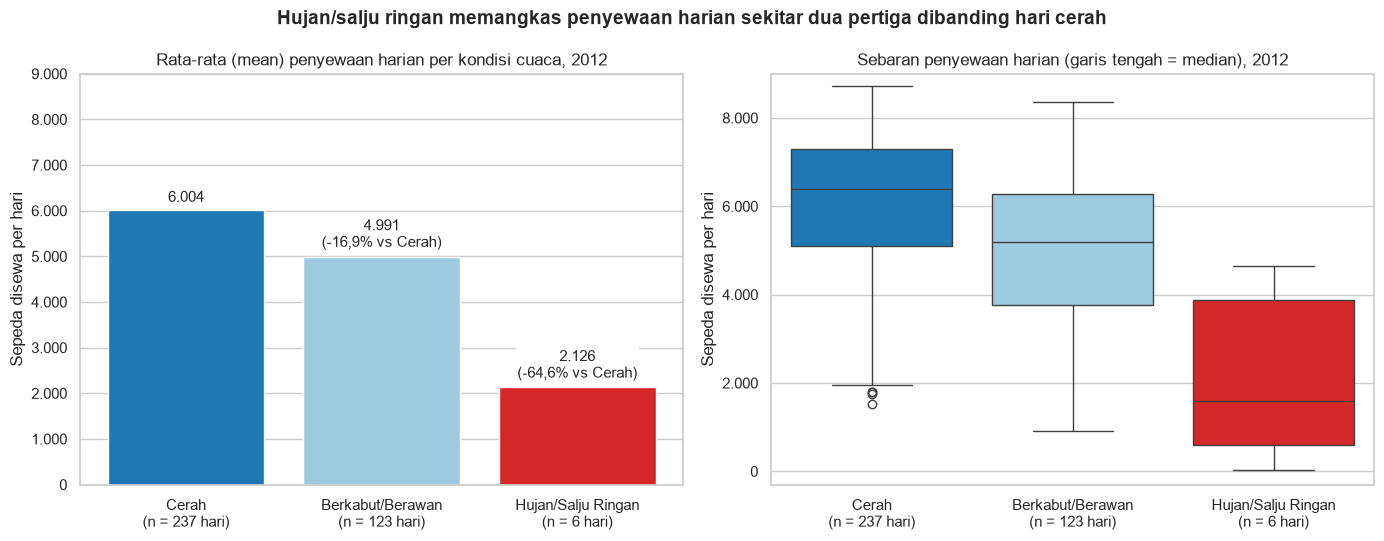

In [27]:
urutan = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]
warna = ["#1f77b4", "#9ecae1", "#d62728"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
label_n = [f"{k}\n(n = {n} hari)" for k, n in zip(urutan, cuaca_2012["jumlah_hari"])]

ax = axes[0]
nilai = cuaca_2012["rata_rata"]
bar = ax.bar(label_n, nilai, color=warna)
for b, v, s in zip(bar, nilai, cuaca_2012["selisih_vs_cerah_%"]):
    teks = rupa(v) + ("" if s == 0 else f"\n({rupa(s, 1)}% vs Cerah)")
    ax.text(b.get_x() + b.get_width() / 2, v + 120, teks, ha="center", va="bottom", fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_title("Rata-rata (mean) penyewaan harian per kondisi cuaca, 2012", fontsize=12)
ax.set_ylabel("Sepeda disewa per hari")
ax.set_ylim(0, 9000)
ax.set_xlabel("")

ax = axes[1]
sns.boxplot(data=day_2012, x="weathersit", y="cnt", order=urutan, palette=warna, hue="weathersit",
            legend=False, saturation=1, ax=ax)
ax.set_xticks(range(3), label_n)
ax.set_title("Sebaran penyewaan harian (garis tengah = median), 2012", fontsize=12)
ax.set_ylabel("Sepeda disewa per hari")
ax.set_xlabel("")
ax.set_ylim(-300, 9000)

for a in axes:
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: rupa(v)))

fig.suptitle("Hujan/salju ringan memangkas penyewaan harian sekitar dua pertiga dibanding hari cerah", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- Grafik batang (dimulai dari nol agar tinggi batang sebanding dengan nilainya) menunjukkan penurunan bertingkat: cerah 6.004, berkabut 4.991 (turun 16,9%), hujan/salju ringan 2.126 (turun 64,6%). Kedua panel memakai skala sumbu Y yang sama supaya bisa dibandingkan langsung.
- Kalau dibaca dari median (lebih tahan terhadap hari ekstrem seperti badai Sandy), penurunannya malah lebih tajam: 6.398 menjadi 1.598, sekitar 75%. Jadi angka "dua pertiga" dari rata-rata adalah perkiraan yang konservatif.
- Boxplot memperlihatkan bahwa rentang hari berkabut masih tumpang tindih dengan hari cerah, sedangkan kotak hujan/salju ringan berada jauh di bawah. Bagi operator, kabut adalah gangguan kecil; hujan adalah kondisi yang mengubah kebutuhan armada secara nyata.

### Pertanyaan 2: Jam berapa permintaan memuncak di hari kerja dan hari libur 2012?

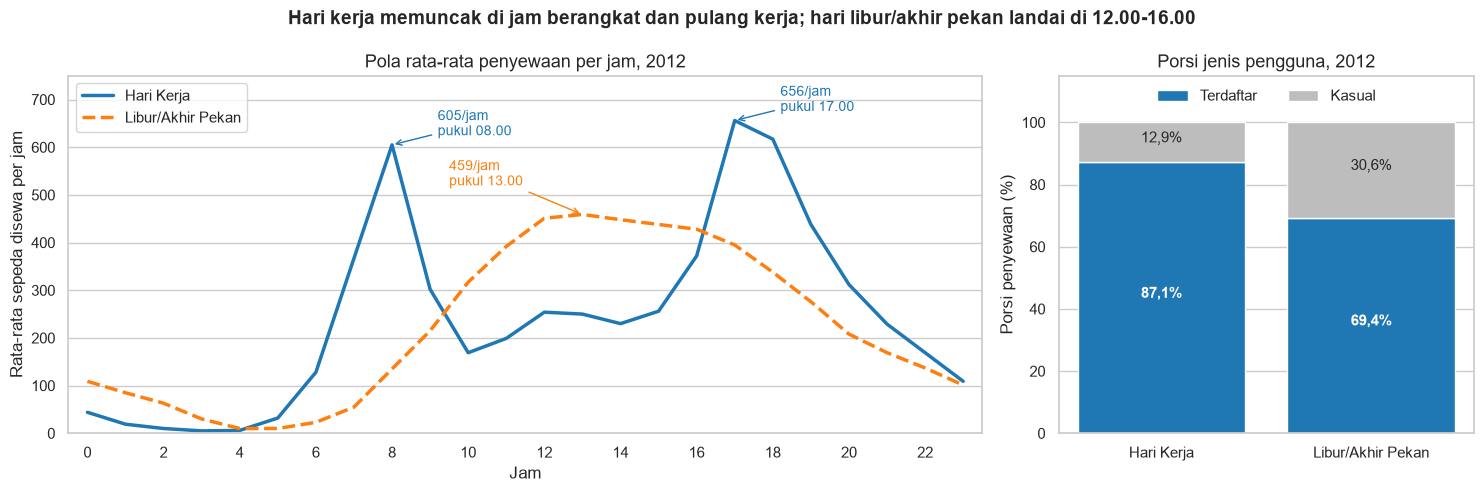

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2.2, 1]})

ax = axes[0]
gaya = {"Hari Kerja": ("#1f77b4", "-"), "Libur/Akhir Pekan": ("#ff7f0e", "--")}
for jenis, (c, ls) in gaya.items():
    ax.plot(pola_jam.index, pola_jam[jenis], color=c, linestyle=ls, linewidth=2.5, label=jenis)
for jam in [8, 17]:
    ax.annotate(f"{rupa(pola_jam.loc[jam, 'Hari Kerja'])}/jam\npukul {jam:02d}.00",
                xy=(jam, pola_jam.loc[jam, "Hari Kerja"]), xytext=(jam + 1.2, pola_jam.loc[jam, "Hari Kerja"] + 20),
                fontsize=10, color="#1f77b4", arrowprops=dict(arrowstyle="->", color="#1f77b4"))
ax.annotate(f"{pola_jam.loc[13, 'Libur/Akhir Pekan']:.0f}/jam\npukul 13.00",
            xy=(13, pola_jam.loc[13, "Libur/Akhir Pekan"]), xytext=(9.5, 520),
            fontsize=10, color="#ff7f0e", arrowprops=dict(arrowstyle="->", color="#ff7f0e"))
ax.set_xticks(range(0, 24, 2))
ax.set_xlim(-0.5, 23.5)
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata sepeda disewa per jam")
ax.set_ylim(0, 750)
ax.set_title("Pola rata-rata penyewaan per jam, 2012", fontsize=13)
ax.legend()

ax = axes[1]
p = porsi[["registered", "casual"]].rename(columns={"registered": "Terdaftar", "casual": "Kasual"})
p = p.div(p.sum(axis=1), axis=0) * 100
p = p.loc[["Hari Kerja", "Libur/Akhir Pekan"]]
ax.bar(p.index, p["Terdaftar"], color="#1f77b4", label="Terdaftar")
ax.bar(p.index, p["Kasual"], bottom=p["Terdaftar"], color="#bdbdbd", label="Kasual")
for i, (r, c) in enumerate(zip(p["Terdaftar"], p["Kasual"])):
    ax.text(i, r / 2, f"{rupa(r, 1)}%", ha="center", color="white", fontsize=11, fontweight="bold")
    ax.text(i, r + c / 2, f"{rupa(c, 1)}%", ha="center", fontsize=11)
ax.set_ylim(0, 115)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("Porsi penyewaan (%)")
ax.set_title("Porsi jenis pengguna, 2012", fontsize=13)
ax.legend(loc="upper center", ncol=2, frameon=False)

fig.suptitle("Hari kerja memuncak di jam berangkat dan pulang kerja; hari libur/akhir pekan landai di 12.00-16.00", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Insight:**
- Garis biru (hari kerja) membentuk dua puncak pada 08.00 dan 17.00, pola klasik perjalanan berangkat dan pulang kerja. Garis oranye putus-putus (libur) naik bertahap dan mendatar di 12.00 sampai 14.00.
- Grafik porsi menunjukkan pengguna kasual naik dari 12,9% di hari kerja menjadi 30,6% di hari libur. Puncak hari kerja digerakkan oleh member; keramaian siang akhir pekan banyak diisi penyewa sekali pakai.

## Analisis Lanjutan: Clustering Manual (Binning)

Teknik yang dipakai adalah **clustering manual tanpa algoritma machine learning**, dengan dua pengelompokan:

1. **Binning suhu**: suhu harian 2012 (°C) dibagi ke empat kelompok dengan batas yang mudah dipahami operator: Dingin (<10°C), Sejuk (10 sampai 20°C), Hangat (20 sampai 30°C), dan Panas (>30°C). Tujuannya melihat apakah ada suhu "terlalu panas" yang justru menurunkan permintaan, informasi yang tidak terlihat jika suhu dibaca sebagai garis lurus.
2. **Segmentasi waktu**: 24 jam dikelompokkan menjadi lima segmen operasional (Dini hari 00-05, Pagi 06-09, Siang 10-15, Sore 16-19, Malam 20-23). Tujuannya memberi tim lapangan satuan kerja per shift, bukan per jam.

In [29]:
day_2012 = day_df[day_df["yr"] == 2012].copy()
day_2012["kelompok_suhu"] = pd.cut(day_2012["temp_c"], bins=[0, 10, 20, 30, 45],
                                   labels=["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"])
suhu = day_2012.groupby("kelompok_suhu", observed=True)["cnt"].agg(jumlah_hari="count", rata_rata="mean").round(0)
suhu

,jumlah_hari,rata_rata
kelompok_suhu,,
Dingin (<10°C),18,2266.0
Sejuk (10-20°C),156,4583.0
Hangat (20-30°C),156,6794.0
Panas (>30°C),36,6501.0


In [30]:
hour_2012 = hour_2012.copy()
hour_2012["segmen_waktu"] = pd.cut(hour_2012["hr"], bins=[-1, 5, 9, 15, 19, 23],
                                   labels=["Dini hari 00-05", "Pagi 06-09", "Siang 10-15", "Sore 16-19", "Malam 20-23"])
segmen = hour_2012.pivot_table(index="segmen_waktu", columns="jenis_hari", values="cnt", aggfunc="sum", observed=True)
segmen_pct = (segmen / segmen.sum() * 100).round(1)
segmen_pct

jenis_hari,Hari Kerja,Libur/Akhir Pekan
segmen_waktu,,
Dini hari 00-05,2.0,5.8
Pagi 06-09,24.2,8.1
Siang 10-15,23.5,47.4
Sore 16-19,36.1,27.2
Malam 20-23,14.2,11.6


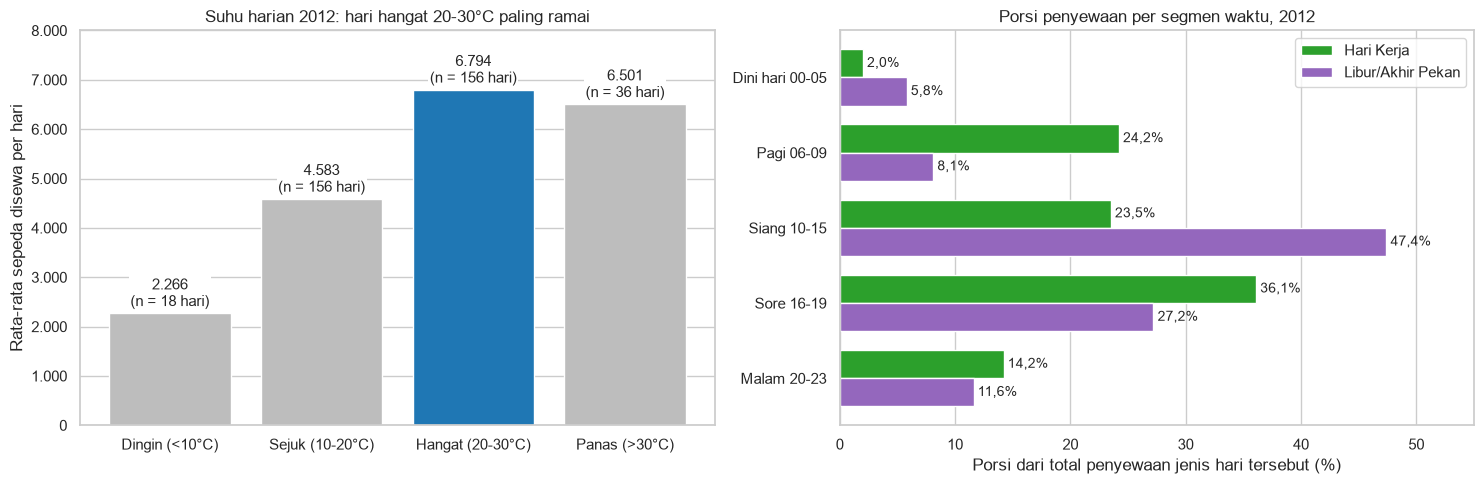

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
warna_suhu = ["#bdbdbd", "#bdbdbd", "#1f77b4", "#bdbdbd"]
b = ax.bar(suhu.index.astype(str), suhu["rata_rata"], color=warna_suhu)
for rect, v, n in zip(b, suhu["rata_rata"], suhu["jumlah_hari"]):
    ax.text(rect.get_x() + rect.get_width() / 2, v + 150, f"{rupa(v)}\n(n = {n} hari)", ha="center", fontsize=11,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: rupa(v)))
ax.set_ylim(0, 8000)
ax.set_ylabel("Rata-rata sepeda disewa per hari")
ax.set_title("Suhu harian 2012: hari hangat 20-30°C paling ramai", fontsize=12)

ax = axes[1]
segmen_pct.plot(kind="barh", ax=ax, color=["#2ca02c", "#9467bd"], width=0.75)
ax.invert_yaxis()
for kontainer in ax.containers:
    ax.bar_label(kontainer, labels=[f"{rupa(v, 1)}%" for v in kontainer.datavalues], padding=3, fontsize=10)
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Porsi dari total penyewaan jenis hari tersebut (%)")
ax.set_ylabel("")
ax.set_xlim(0, 55)
ax.set_title("Porsi penyewaan per segmen waktu, 2012", fontsize=12)
ax.legend(title="")

plt.tight_layout()
plt.show()

**Insight:**
- Hari hangat (20 sampai 30°C) rata-rata mencatat 6.794 penyewaan, tiga kali lipat hari dingin (2.266). Di atas 30°C rata-ratanya 6.501, turun sekitar 4%. Selisih sekecil itu dari 36 hari belum cukup kuat disebut penurunan; yang aman disimpulkan adalah permintaan berhenti naik setelah 30°C.
- Batas kelompok memakai interval tertutup kanan dari `pd.cut`: 20°C masuk Sejuk, 30°C masuk Hangat.
- Pada hari kerja, segmen sore (16-19) menyumbang porsi terbesar, disusul pagi (06-09). Pada akhir pekan, hampir setengah penyewaan terjadi di segmen siang (10-15). Segmen Siang dan Dini hari masing-masing 6 jam, sedangkan segmen lain 4 jam; setelah dihitung per jam pun Siang tetap terpadat di hari libur (sekitar 7,9% per jam). Pembagian shift redistribusi sebaiknya mengikuti dua pola yang berbeda ini.

## Menyimpan Data Bersih untuk Dashboard

Dashboard memakai data per jam yang sudah dibersihkan, ditambah kondisi cuaca dan suhu versi harian agar analisis cuaca di dashboard dihitung per hari, sama seperti Pertanyaan 1.

In [32]:
harian_ref = day_df[["dteday", "weathersit", "temp_c"]].rename(
    columns={"weathersit": "weathersit_harian", "temp_c": "temp_c_harian"})
main_data = hour_df[["dteday", "hr", "jenis_hari", "casual", "registered", "cnt"]].merge(harian_ref, on="dteday")
main_data.to_csv("dashboard/main_data.csv", index=False)
print(main_data.shape, "| total cnt:", main_data["cnt"].sum())

(17379, 8) | total cnt: 3292679


## Conclusion

- **Kesimpulan Pertanyaan 1:** Sepanjang 2012, cuaca berkabut/berawan menurunkan rata-rata penyewaan harian 16,9% (6.004 menjadi 4.991), sedangkan hujan/salju ringan menurunkannya 64,6% (menjadi 2.126). Hujan adalah satu-satunya kondisi cuaca yang memangkas permintaan secara besar; kabut hanya menggeser sedikit. Catatan keterbatasan: hari hujan di 2012 cuma 6 hari, sehingga besaran persisnya bisa berubah bila datanya bertambah, walau mediannya menunjukkan arah yang sama.
- **Kesimpulan Pertanyaan 2:** Di hari kerja 2012, permintaan memuncak pada pukul 08.00 (605 sepeda/jam) dan 17.00 sampai 18.00 (656 dan 617 sepeda/jam), dengan 87,1% penyewaan berasal dari pengguna terdaftar. Di hari libur/akhir pekan, puncaknya landai di 12.00 sampai 14.00 (sekitar 450 sepeda/jam) dan porsi pengguna kasual naik menjadi 30,6%.
- **Dari analisis lanjutan:** permintaan paling tinggi di suhu 20 sampai 30°C dan berhenti naik di atas 30°C.

**Rekomendasi (action item):**
1. **Jadwalkan perawatan armada di hari dengan prakiraan hujan.** Pada hari hujan, sekitar dua pertiga armada menganggur, jadi itu waktu paling murah untuk menarik sepeda ke bengkel tanpa kehilangan pendapatan. Hari berkabut tidak perlu diperlakukan khusus.
2. **Isi ulang stasiun sebelum pukul 07.00 dan 16.00 di hari kerja.** Dua jendela ini datang tepat sebelum puncak 08.00 dan 17.00; redistribusi yang terlambat satu jam berarti stasiun kosong saat permintaan tertinggi.
3. **Arahkan promosi keanggotaan ke penyewa kasual akhir pekan, siang hari.** Mereka hampir sepertiga penyewa akhir pekan dan datang pada jam yang bisa diprediksi (12.00 sampai 14.00), sehingga penawaran konversi member di aplikasi atau di stasiun pada jam itu punya sasaran yang jelas.